In [ ]:
!unzip /content/drive/MyDrive/testimages.zip

Archive:  /content/drive/MyDrive/testimages.zip
   creating: testimages/
   creating: testimages/TEST/
   creating: testimages/TEST/EOSINOPHIL/
  inflating: testimages/TEST/EOSINOPHIL/_0_1616.jpeg  
  inflating: testimages/TEST/EOSINOPHIL/_0_1794.jpeg  
  inflating: testimages/TEST/EOSINOPHIL/_0_1845.jpeg  
  inflating: testimages/TEST/EOSINOPHIL/_0_187.jpeg  
  inflating: testimages/TEST/EOSINOPHIL/_0_196.jpeg  
  inflating: testimages/TEST/EOSINOPHIL/_0_2107.jpeg  
  inflating: testimages/TEST/EOSINOPHIL/_0_2183.jpeg  
  inflating: testimages/TEST/EOSINOPHIL/_0_2313.jpeg  
  inflating: testimages/TEST/EOSINOPHIL/_0_2498.jpeg  
  inflating: testimages/TEST/EOSINOPHIL/_0_2634.jpeg  
  inflating: testimages/TEST/EOSINOPHIL/_0_2789.jpeg  
  inflating: testimages/TEST/EOSINOPHIL/_0_2963.jpeg  
  inflating: testimages/TEST/EOSINOPHIL/_0_3083.jpeg  
  inflating: testimages/TEST/EOSINOPHIL/_0_3249.jpeg  
  inflating: testimages/TEST/EOSINOPHIL/_0_3809.jpeg  
  inflating: testimages/TEST/EOSI

GPU found


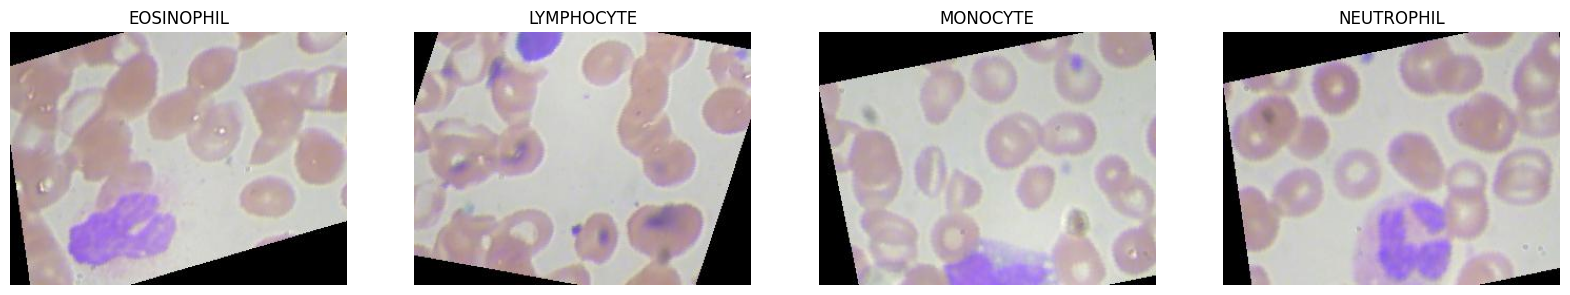

Found 7968 images belonging to 4 classes.
Found 1989 images belonging to 4 classes.
Found 2487 images belonging to 4 classes.
Epoch 1/25
249/249 [==============================] - ETA: 0s - loss: 1.7484 - accuracy: 0.4354

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


249/249 [==============================] - 61s 213ms/step - loss: 1.7484 - accuracy: 0.4354 - val_loss: 15.3144 - val_accuracy: 0.2490 - lr: 0.0010
Epoch 2/25
249/249 [==============================] - 50s 202ms/step - loss: 0.8523 - accuracy: 0.6510 - val_loss: 1.4451 - val_accuracy: 0.4909 - lr: 0.0010
Epoch 3/25
249/249 [==============================] - 53s 212ms/step - loss: 0.6107 - accuracy: 0.7608 - val_loss: 0.9894 - val_accuracy: 0.6069 - lr: 0.0010
Epoch 4/25
249/249 [==============================] - 50s 203ms/step - loss: 0.4846 - accuracy: 0.8100 - val_loss: 23.0977 - val_accuracy: 0.3301 - lr: 0.0010
Epoch 5/25
249/249 [==============================] - 52s 209ms/step - loss: 0.4162 - accuracy: 0.8360 - val_loss: 0.7283 - val_accuracy: 0.7182 - lr: 0.0010
Epoch 6/25
249/249 [==============================] - 52s 210ms/step - loss: 0.3787 - accuracy: 0.8555 - val_loss: 19.4540 - val_accuracy: 0.3453 - lr: 0.0010
Epoch 7/25
249/249 [==============================] - 51s 20

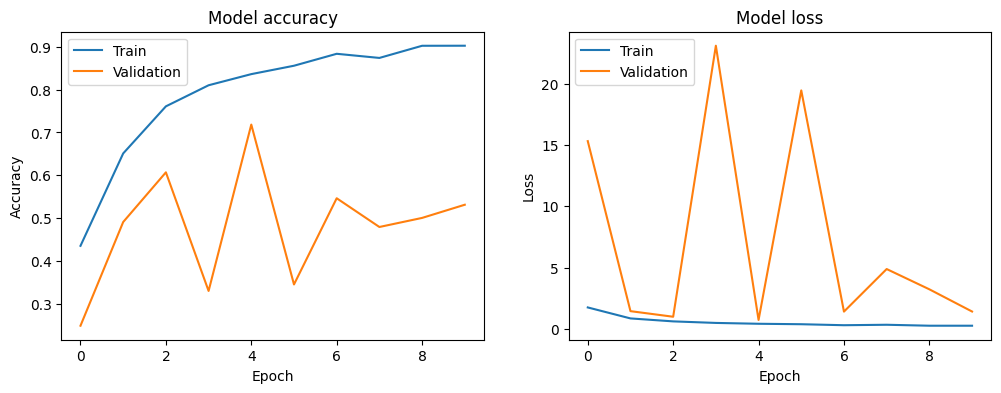

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import cv2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, LearningRateScheduler

# Check if GPU is available
if tf.test.gpu_device_name():
    print('GPU found')
else:
    print("No GPU found")

# Define paths
base_dir = '/content/final'
train_dir = os.path.join(base_dir, 'TRAIN')
test_dir = os.path.join(base_dir, 'TEST')
classes = ['EOSINOPHIL', 'LYMPHOCYTE', 'MONOCYTE', 'NEUTROPHIL']

# Load and display sample images
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for i, cell_type in enumerate(classes):
    img_path = os.path.join(train_dir, cell_type, os.listdir(os.path.join(train_dir, cell_type))[0])
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[i].imshow(img)
    axes[i].set_title(cell_type)
    axes[i].axis('off')
plt.show()

# Image data generator with data augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    validation_split=0.2  # 20% of the training data for validation
)

test_datagen = ImageDataGenerator(rescale=1./255)

# Create training and validation generators
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

validation_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

# Create test generator
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical'
)

# Build a more complex CNN model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Conv2D(256, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(4, activation='softmax')  # 4 classes: Eosinophil, Lymphocyte, Monocyte, Neutrophil
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Callbacks
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
model_checkpoint = ModelCheckpoint('best_blood_cell_classifier.h5', save_best_only=True, monitor='val_loss')

# Learning rate scheduler
def scheduler(epoch, lr):
    if epoch < 10:
        return lr
    else:
        return lr * tf.math.exp(-0.1)

lr_scheduler = LearningRateScheduler(scheduler)

# Train the model
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // validation_generator.batch_size,
    epochs=25,  # Increase the number of epochs
    callbacks=[early_stopping, model_checkpoint, lr_scheduler]
)

# Evaluate the model on the test set
loss, accuracy = model.evaluate(test_generator)
print(f'Test Loss: {loss}')
print(f'Test Accuracy: {accuracy}')

# Plot training & validation accuracy values
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.show()

# Save the trained model
model.save('blood_cell_classifier_level_3rd.h5')


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import load_model

# Define paths
base_dir = '/content/final'

test_dir = os.path.join(base_dir, 'TEST')
classes = ['EOSINOPHIL', 'LYMPHOCYTE', 'MONOCYTE', 'NEUTROPHIL']

# Image data generator for the test set
test_datagen = ImageDataGenerator(rescale=1./255)

# Create test generator
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical'
)

# Load the trained model
model = load_model('best_blood_cell_classifier.h5')

# Evaluate the model on the test set
loss, accuracy = model.evaluate(test_generator)
print(f'Test Loss: {loss}')
print(f'Test Accuracy: {accuracy}')

# Predict on the test set
test_generator.reset()
predictions = model.predict(test_generator, steps=test_generator.samples // test_generator.batch_size, verbose=1)
predicted_classes = np.argmax(predictions, axis=1)

# Get the true labels
true_classes = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

# Plot confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import pandas as pd

conf_matrix = confusion_matrix(true_classes, predicted_classes)
df_cm = pd.DataFrame(conf_matrix, index=class_labels, columns=class_labels)
plt.figure(figsize=(10, 7))
sns.heatmap(df_cm, annot=True, fmt='d', cmap='Blues')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Classification Report
from sklearn.metrics import classification_report

print('Classification Report')
print(classification_report(true_classes, predicted_classes, target_names=class_labels))


Found 2487 images belonging to 4 classes.
78/78 [==============================] - 3s 41ms/step - loss: 1.3750 - accuracy: 0.6976
Test Loss: 1.3749817609786987
Test Accuracy: 0.6976276636123657
77/77 [==============================] - 2s 28ms/step


ValueError: Found input variables with inconsistent numbers of samples: [2487, 2464]

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.models import load_model

# Load the saved model
model = load_model('best_blood_cell_classifier.h5')

# Define paths
base_dir = '/content/final'

test_dir = os.path.join(base_dir, 'TEST')
classes = ['EOSINOPHIL', 'LYMPHOCYTE', 'MONOCYTE', 'NEUTROPHIL']

# Create test data generator
test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    shuffle=False  # Important: do not shuffle the data for evaluation
)

# Evaluate the model on the test set
loss, accuracy = model.evaluate(test_generator)
print(f'Test Loss: {loss}')
print(f'Test Accuracy: {accuracy}')

# Function to load and preprocess individual images for prediction
def prepare_image(file):
    img_path = os.path.join(test_dir, file)
    img = load_img(img_path, target_size=(128, 128))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
    img_array = img_array / 255.0  # Rescale
    return img_array

# Test the model with individual images
test_images = [
    '/EOSINOPHIL/_0_187',  # Replace with your test image paths
    '/LYMPHOCYTE/_0_33.jpeg'

]

for img_path in test_images:
    img_array = prepare_image(img_path)
    predictions = model.predict(img_array)
    predicted_class = np.argmax(predictions, axis=1)
    predicted_label = classes[predicted_class[0]]
    print(f'Predicted class for {img_path}: {predicted_label}')

# Plot some test images with predictions
plt.figure(figsize=(12, 12))
for i, img_path in enumerate(test_images):
    img = load_img(os.path.join(test_dir, img_path), target_size=(128, 128))
    plt.subplot(2, 2, i+1)
    plt.imshow(img)
    plt.title(f'Predicted: {predicted_label}')
    plt.axis('off')
plt.show()


OSError: No file or directory found at best_blood_cell_classifier.h5

GPU found


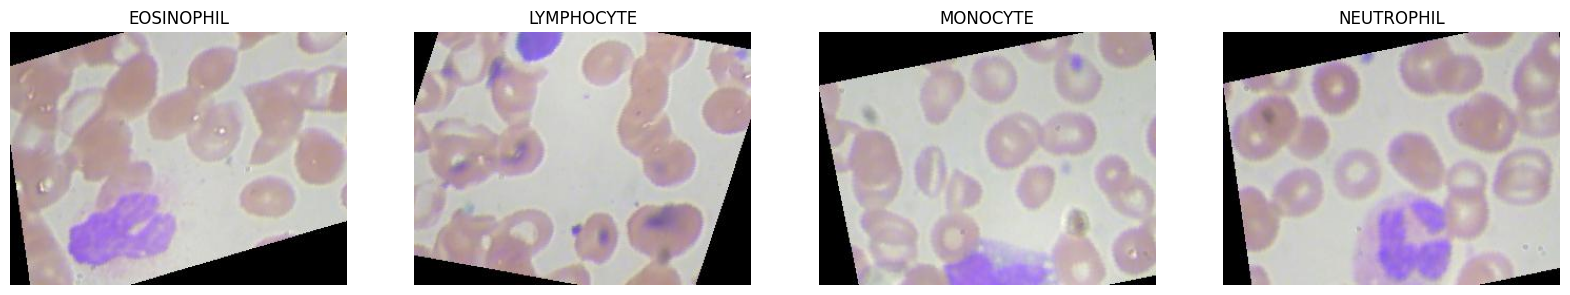

Found 7968 images belonging to 4 classes.
Found 1989 images belonging to 4 classes.
Found 2487 images belonging to 4 classes.
Epoch 1/25
249/249 [==============================] - ETA: 0s - loss: 9.2367 - accuracy: 0.2928

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


249/249 [==============================] - 61s 212ms/step - loss: 9.2367 - accuracy: 0.2928 - val_loss: 9.3516 - val_accuracy: 0.2485 - lr: 4.5242e-04
Epoch 2/25
249/249 [==============================] - 52s 210ms/step - loss: 4.9798 - accuracy: 0.3741 - val_loss: 4.5390 - val_accuracy: 0.3256 - lr: 4.0937e-04
Epoch 3/25
249/249 [==============================] - 52s 207ms/step - loss: 3.1620 - accuracy: 0.4864 - val_loss: 4.6691 - val_accuracy: 0.2903 - lr: 3.7041e-04
Epoch 4/25
249/249 [==============================] - 52s 210ms/step - loss: 2.2239 - accuracy: 0.5894 - val_loss: 3.2873 - val_accuracy: 0.5207 - lr: 3.3516e-04
Epoch 5/25
249/249 [==============================] - 53s 211ms/step - loss: 1.6525 - accuracy: 0.6998 - val_loss: 8.0210 - val_accuracy: 0.2818 - lr: 3.0327e-04
Epoch 6/25
249/249 [==============================] - 52s 211ms/step - loss: 1.3019 - accuracy: 0.7598 - val_loss: 14.2442 - val_accuracy: 0.3816 - lr: 2.7441e-04
Epoch 7/25
249/249 [==================

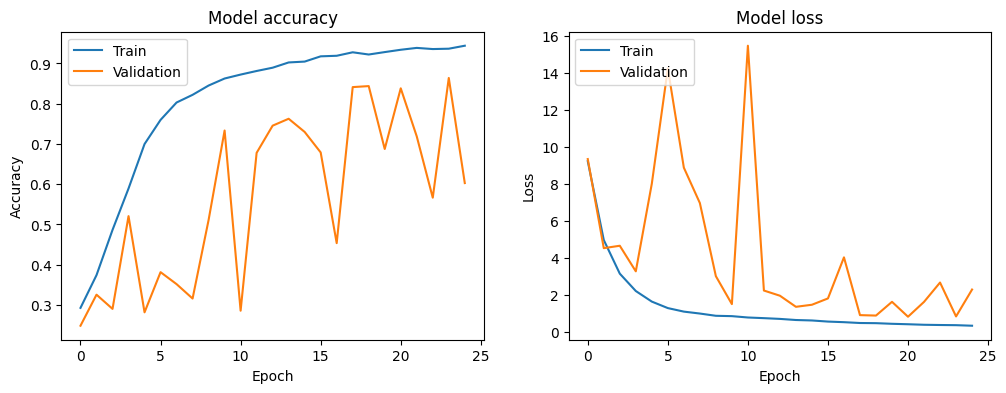

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import cv2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, LearningRateScheduler

# Check if GPU is available
if tf.test.gpu_device_name():
    print('GPU found')
else:
    print("No GPU found")

# Define paths
base_dir = '/content/file'
train_dir = os.path.join(base_dir, 'TRAIN')
test_dir = os.path.join(base_dir, 'TEST')
classes = ['EOSINOPHIL', 'LYMPHOCYTE', 'MONOCYTE', 'NEUTROPHIL']

# Load and display sample images
fig, axes = plt.subplots(5, 20, figsize=(20, 5))
for i, cell_type in enumerate(classes):
    img_path = os.path.join(train_dir, cell_type, os.listdir(os.path.join(train_dir, cell_type))[0])
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[i].imshow(img)
    axes[i].set_title(cell_type)
    axes[i].axis('off')
plt.show()

# Image data generator with data augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    validation_split=0.2  # 20% of the training data for validation
)

test_datagen = ImageDataGenerator(rescale=1./255)

# Create training and validation generators
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

validation_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

# Create test generator
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical'
)

# Build a more complex CNN model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),
    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),
    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),
    Conv2D(256, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.5),
    Flatten(),
    Dense(512, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01)),
    Dropout(0.5),
    Dense(4, activation='softmax')  # 4 classes: Eosinophil, Lymphocyte, Monocyte, Neutrophil
])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005), loss='categorical_crossentropy', metrics=['accuracy'])

# Callbacks
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
model_checkpoint = ModelCheckpoint('best_blood_cell_classifier_9pm.h5', save_best_only=True, monitor='val_loss')

# Learning rate scheduler
def scheduler(epoch, lr):
    return lr * tf.math.exp(-0.1)

lr_scheduler = LearningRateScheduler(scheduler)

# Train the model
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // validation_generator.batch_size,
    epochs=25,  # Increase the number of epochs
    callbacks=[early_stopping, model_checkpoint, lr_scheduler]
)

# Evaluate the model on the test set
loss, accuracy = model.evaluate(test_generator)
print(f'Test Loss: {loss}')
print(f'Test Accuracy: {accuracy}')

# Plot training & validation accuracy values
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.show()

# Save the trained model
model.save('blood_cell_classifier_9pm.h5')


Found 2487 images belonging to 4 classes.
Amit 1
78/78 [==============================] - 3s 31ms/step - loss: 1.6677 - accuracy: 0.7616
Test Loss: 1.6677110195159912
Test Accuracy: 0.7615601420402527
Amit 2
1/1 [==============================] - 0s 156ms/step
Predicted class for 1.jpg: NEUTROPHIL
1/1 [==============================] - 0s 27ms/step
Predicted class for 11.jpg: NEUTROPHIL
1/1 [==============================] - 0s 26ms/step
Predicted class for 15.jpg: MONOCYTE
1/1 [==============================] - 0s 24ms/step
Predicted class for 20.jpg: LYMPHOCYTE
1/1 [==============================] - 0s 27ms/step


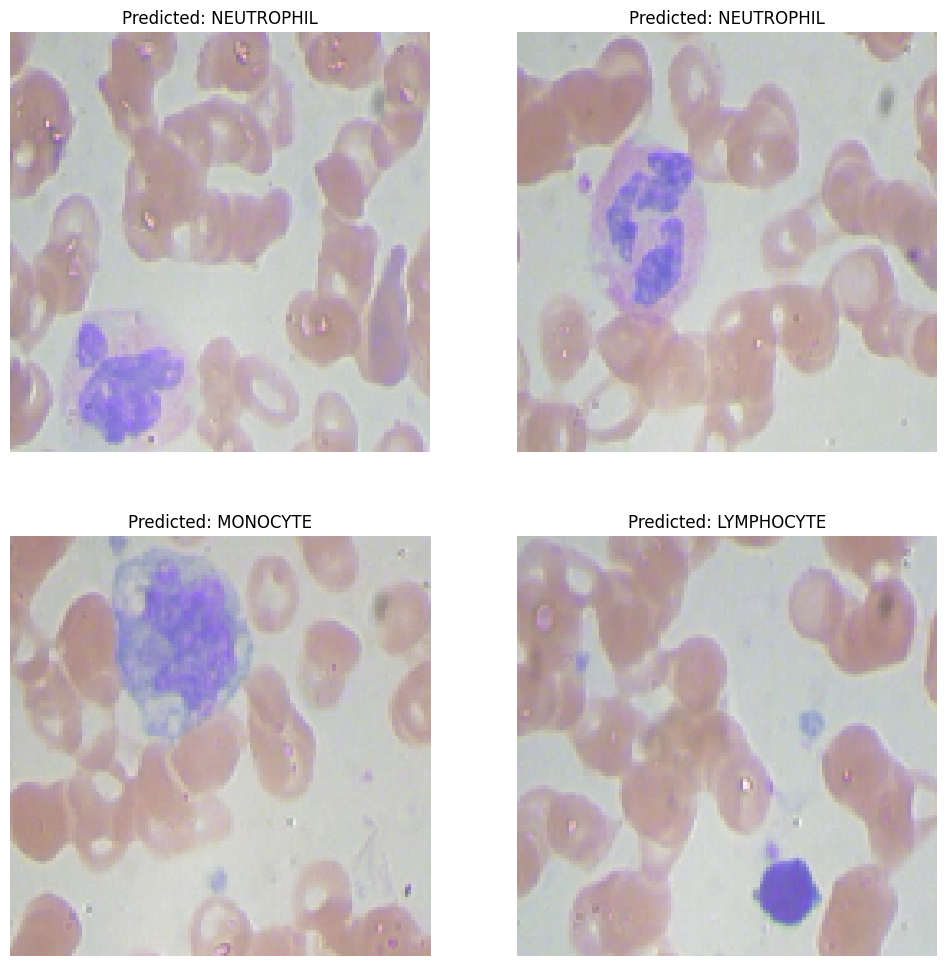

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.models import load_model

# Load the saved model
model = load_model('best_blood_cell_classifier_9pm.h5')

# Define paths
base_dir = '/content/file'
test_dir = os.path.join(base_dir, 'TEST')
# classes = ['Eosinophil', 'Lymphocyte', 'Monocyte', 'Neutrophil']
classes = ['EOSINOPHIL', 'LYMPHOCYTE', 'MONOCYTE', 'NEUTROPHIL']

# Create test data generator
test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    shuffle=False  # Important: do not shuffle the data for evaluation
)
print('Amit 1')
# Evaluate the model on the test set
loss, accuracy = model.evaluate(test_generator)
print(f'Test Loss: {loss}')
print(f'Test Accuracy: {accuracy}')

# Function to load and preprocess individual images for prediction
def prepare_image(file):
    img_path = os.path.join(test_dir, file)
    img = load_img(img_path, target_size=(128, 128))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
    img_array = img_array / 255.0  # Rescale
    return img_array
print('Amit 2')
# Test the model with individual images
test_images = [
    '1.jpg',  # Replace with your test image paths
    '11.jpg',
    '15.jpg',
    '20.jpg'
]

for img_path in test_images:
    img_array = prepare_image(img_path)
    predictions = model.predict(img_array)
    predicted_class = np.argmax(predictions, axis=1)
    predicted_label = classes[predicted_class[0]]
    print(f'Predicted class for {img_path}: {predicted_label}')

# Plot some test images with predictions
plt.figure(figsize=(12, 12))
for i, img_path in enumerate(test_images):
    img = load_img(os.path.join(test_dir, img_path), target_size=(128, 128))
    plt.subplot(2, 2, i+1)
    plt.imshow(img)
    img_array = prepare_image(img_path)
    predictions = model.predict(img_array)
    predicted_class = np.argmax(predictions, axis=1)
    predicted_label = classes[predicted_class[0]]
    plt.title(f'Predicted: {predicted_label}')
    plt.axis('off')
plt.show()


In [ ]:
# random images

In [1]:
!unzip /content/drive/MyDrive/file_images_model_9pm.zip

Streaming output truncated to the last 5000 lines.
  inflating: TRAIN/LYMPHOCYTE/_16_5333.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_18_6659.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_3_6773.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_14_5991.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_10_4486.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_18_4594.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_12_6731.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_21_3317.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_22_1298.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_1_1652.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_2_4727.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_4_7616.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_20_6964.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_22_5329.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_3_1845.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_9_5348.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_3_9310.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_11_9847.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_24_9788.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_25_9181.jpeg  
  inflating: TRAIN/LYMPHOCYTE/_2_940

1/1 [==============================] - 0s 267ms/step
Predicted class for BloodImage_00206.jpg: LYMPHOCYTE with confidence 0.9997057318687439
1/1 [==============================] - 0s 67ms/step


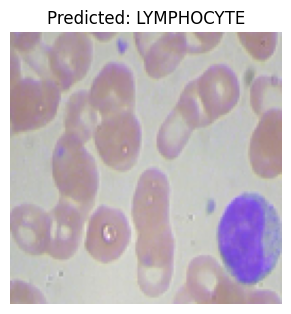

In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.models import load_model

# Load the saved model
model = load_model('best_blood_cell_classifier_9pm.h5')

# Define paths
base_dir = '/content/file'
test_dir = os.path.join(base_dir, 'TEST')
# classes = ['Eosinophil', 'Lymphocyte', 'Monocyte', 'Neutrophil']
classes = ['EOSINOPHIL', 'LYMPHOCYTE', 'MONOCYTE', 'NEUTROPHIL']

# Confidence threshold for unknown images
CONFIDENCE_THRESHOLD = 0.7

# Function to load and preprocess individual images for prediction
def prepare_image(file_path):
    img = load_img(file_path, target_size=(128, 128))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
    img_array = img_array / 255.0  # Rescale
    return img_array

# Test the model with individual images
test_images = [
    'BloodImage_00206.jpg'  # An example of a non-blood cell image
]

for img_path in test_images:
    img_array = prepare_image(os.path.join(test_dir, img_path))
    predictions = model.predict(img_array)
    max_confidence = np.max(predictions)
    predicted_class = np.argmax(predictions, axis=1)
    if max_confidence < CONFIDENCE_THRESHOLD:
        predicted_label = 'Unknown/Not a blood cell'
    else:
        predicted_label = classes[predicted_class[0]]
    print(f'Predicted class for {img_path}: {predicted_label} with confidence {max_confidence}')

# Plot some test images with predictions
plt.figure(figsize=(12, 12))
for i, img_path in enumerate(test_images):
    img = load_img(os.path.join(test_dir, img_path), target_size=(128, 128))
    plt.subplot(3, 3, i+1)
    plt.imshow(img)
    img_array = prepare_image(os.path.join(test_dir, img_path))
    predictions = model.predict(img_array)
    max_confidence = np.max(predictions)
    predicted_class = np.argmax(predictions, axis=1)
    if max_confidence < CONFIDENCE_THRESHOLD:
        predicted_label = 'Unknown/Not a blood cell please submitonly a bloodcell image'
    else:
        predicted_label = classes[predicted_class[0]]
    plt.title(f'Predicted: {predicted_label}')
    plt.axis('off')
plt.show()
